In [1]:
import pandas as pd

hechos = pd.read_csv('../data/siniestros_viales_hechos.csv', encoding='utf-8-sig', sep=';', low_memory=False)
victimas = pd.read_csv('../data/siniestros_viales_victimas.csv', encoding='utf-8-sig', sep=';', low_memory=False)

print('Hechos:', hechos.shape)
print('Víctimas:', victimas.shape)

Hechos: (65818, 21)
Víctimas: (75197, 9)


In [2]:
hechos = hechos[hechos['modo_desplazamiento_victima'] != '#¡REF!'].copy()

columnas_texto_hechos = ['modo_desplazamiento_victima', 'gravedad_siniestro', 'tipo_de_via_siniestro']
for col in columnas_texto_hechos:
    hechos[col] = hechos[col].str.strip().str.upper()

columnas_texto_victimas = ['modo_desplazamiento_victima', 'GRAVEdad_victima', 'rol_victima']
for col in columnas_texto_victimas:
    victimas[col] = victimas[col].str.strip().str.upper()

print(hechos['modo_desplazamiento_victima'].value_counts())

modo_desplazamiento_victima
MOTO                  24555
SD                    10928
PEATON                 9415
BICICLETA              7091
AUTO                   7073
TRANSPORTE PUBLICO     3633
TAXI                    810
UTILITARIO              697
MOVIL                   531
MIXTO                   498
CAMION                  250
MONOPATIN               207
OTRO                    129
Name: count, dtype: int64


In [3]:
import re

def normalizar_comuna(valor):
    if pd.isna(valor):
        return None
    match = re.search(r'\d+', str(valor))
    return int(match.group()) if match else None

hechos['comuna'] = hechos['comuna_siniestro'].apply(normalizar_comuna)
print(hechos['comuna'].value_counts().sort_index())

comuna
1.0     7241
2.0     2350
3.0     4858
4.0     4562
5.0     3285
6.0     2772
7.0     4368
8.0     3088
9.0     4450
10.0    3776
11.0    3531
12.0    4310
13.0    3965
14.0    4496
15.0    5214
Name: count, dtype: int64


In [4]:
hechos_geo = hechos.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()
hechos_geo['latitud_siniestro'] = hechos_geo['latitud_siniestro'].astype(float)
hechos_geo['longitud_siniestro'] = hechos_geo['longitud_siniestro'].astype(float)

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')hechos_geo = hechos.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()
hechos_geo['latitud_siniestro'] = hechos_geo['latitud_siniestro'].astype(float)
hechos_geo['longitud_siniestro'] = hechos_geo['longitud_siniestro'].astype(float)

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')

SyntaxError: invalid syntax (1679950593.py, line 5)

In [5]:
hechos_geo = hechos.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()
hechos_geo['latitud_siniestro'] = hechos_geo['latitud_siniestro'].astype(float)
hechos_geo['longitud_siniestro'] = hechos_geo['longitud_siniestro'].astype(float)

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')

ValueError: could not convert string to float: 'SD'

In [6]:
hechos_geo = hechos.copy()
hechos_geo['latitud_siniestro'] = pd.to_numeric(hechos_geo['latitud_siniestro'], errors='coerce')
hechos_geo['longitud_siniestro'] = pd.to_numeric(hechos_geo['longitud_siniestro'], errors='coerce')
hechos_geo = hechos_geo.dropna(subset=['latitud_siniestro', 'longitud_siniestro']).copy()

print(f'{len(hechos_geo)} de {len(hechos)} siniestros tienen coordenadas ({len(hechos_geo)/len(hechos)*100:.1f}%)')

62787 de 65817 siniestros tienen coordenadas (95.4%)


In [7]:
motos = hechos_geo[hechos_geo['modo_desplazamiento_victima'] == 'MOTO'].copy()
print(f'{len(motos)} siniestros de motociclistas con coordenadas válidas')
print()
print(motos['gravedad_siniestro'].value_counts())

23343 siniestros de motociclistas con coordenadas válidas

gravedad_siniestro
LEVE      21756
GRAVE      1304
MORTAL      283
Name: count, dtype: int64


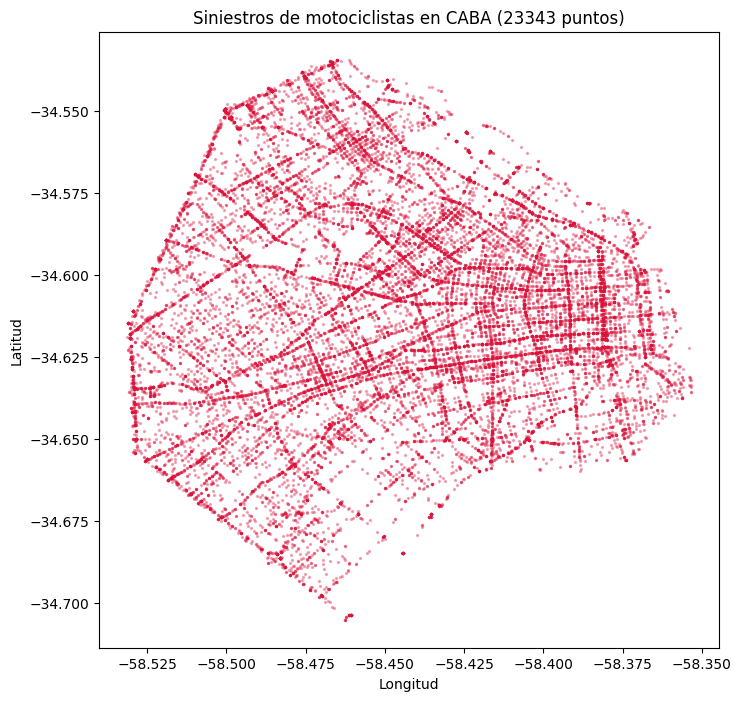

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(motos['longitud_siniestro'], motos['latitud_siniestro'], s=2, alpha=0.3, c='crimson')
ax.set_title(f'Siniestros de motociclistas en CABA ({len(motos)} puntos)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
plt.show()

In [9]:
motos.to_csv('../data/motos_limpio.csv', index=False)
print('Guardado en data/motos_limpio.csv')

Guardado en data/motos_limpio.csv


In [11]:
from sklearn.cluster import DBSCAN
import numpy as np

# DBSCAN con distancia haversine necesita las coordenadas en radianes
coords = motos[['latitud_siniestro', 'longitud_siniestro']].values
coords_rad = np.radians(coords)

# eps en radianes: 300 metros / radio de la Tierra en metros
eps_metros = 300
eps_rad = eps_metros / 6371000

db = DBSCAN(eps=eps_rad, min_samples=8, metric='haversine').fit(coords_rad)
motos['cluster'] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_ruido = list(db.labels_).count(-1)

print(f'{n_clusters} hotspots encontrados')
print(f'{n_ruido} siniestros aislados (sin hotspot cercano) de {len(motos)}')

10 hotspots encontrados
79 siniestros aislados (sin hotspot cercano) de 23343


In [12]:
tamanos = motos[motos['cluster'] != -1]['cluster'].value_counts().sort_values(ascending=False)
print(tamanos)

cluster
0    23068
7       35
5       32
2       27
3       25
8       20
6       16
4       15
1       13
9       13
Name: count, dtype: int64


In [13]:
eps_metros = 60  # ~una cuadra
min_muestras = 10  # al menos 10 siniestros históricos para considerarlo un hotspot real

eps_rad = eps_metros / 6371000
db = DBSCAN(eps=eps_rad, min_samples=min_muestras, metric='haversine').fit(coords_rad)
motos['cluster'] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_ruido = list(db.labels_).count(-1)

print(f'{n_clusters} hotspots encontrados')
print(f'{n_ruido} siniestros aislados de {len(motos)} ({n_ruido/len(motos)*100:.1f}%)')
print()
tamanos = motos[motos['cluster'] != -1]['cluster'].value_counts().sort_values(ascending=False)
print(tamanos.head(15))

430 hotspots encontrados
15846 siniestros aislados de 23343 (67.9%)

cluster
353    88
6      84
144    71
10     58
237    58
60     57
107    55
78     53
31     53
7      52
40     46
79     45
4      45
130    43
115    41
Name: count, dtype: int64


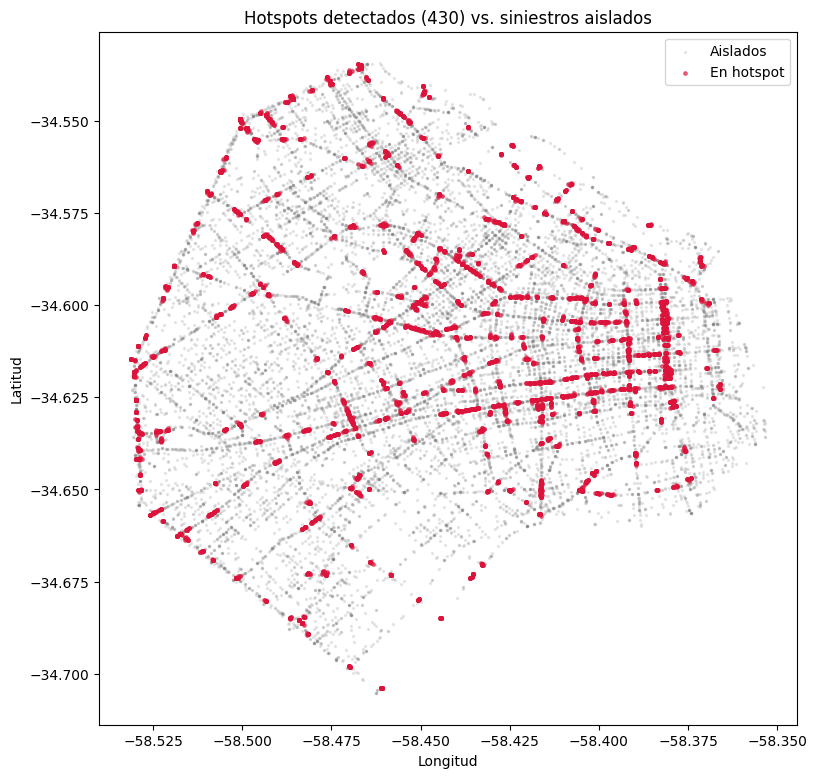

In [14]:
fig, ax = plt.subplots(figsize=(9, 9))

ruido = motos[motos['cluster'] == -1]
en_cluster = motos[motos['cluster'] != -1]

ax.scatter(ruido['longitud_siniestro'], ruido['latitud_siniestro'], s=2, alpha=0.15, c='gray', label='Aislados')
ax.scatter(en_cluster['longitud_siniestro'], en_cluster['latitud_siniestro'], s=6, alpha=0.6, c='crimson', label='En hotspot')

ax.set_title(f'Hotspots detectados (430) vs. siniestros aislados')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend()
plt.show()

In [15]:
motos.to_csv('../data/motos_con_clusters.csv', index=False)

hotspots_resumen = motos[motos['cluster'] != -1].groupby('cluster').agg(
    latitud=('latitud_siniestro', 'mean'),
    longitud=('longitud_siniestro', 'mean'),
    cantidad_siniestros=('cluster', 'count'),
    mortales=('gravedad_siniestro', lambda x: (x == 'MORTAL').sum()),
    graves=('gravedad_siniestro', lambda x: (x == 'GRAVE').sum()),
).reset_index().sort_values('cantidad_siniestros', ascending=False)

hotspots_resumen.to_csv('../data/hotspots_moto_caba.csv', index=False)
print(f'{len(hotspots_resumen)} hotspots guardados')
print()
print(hotspots_resumen.head(10))

430 hotspots guardados

     cluster    latitud   longitud  cantidad_siniestros  mortales  graves
353      353 -34.549708 -58.500494                   88         3       4
6          6 -34.622148 -58.380791                   84         2       6
144      144 -34.630270 -58.469824                   71         0       2
237      237 -34.618037 -58.380817                   58         1       3
10        10 -34.619753 -58.380774                   58         0       1
60        60 -34.604209 -58.381179                   57         0       3
107      107 -34.569993 -58.509020                   55         1       1
78        78 -34.607607 -58.445905                   53         0       0
31        31 -34.543852 -58.485876                   53         0       4
7          7 -34.548608 -58.493121                   52         4       4


In [16]:
import requests
import time

def geocodificar_inverso(lat, lng):
    url = f'https://nominatim.openstreetmap.org/reverse?lat={lat}&lon={lng}&format=json&accept-language=es'
    r = requests.get(url, headers={'User-Agent': 'MotoSafeGBA-Tesis/1.0'})
    data = r.json()
    return data.get('display_name', 'Sin dirección')

top10 = hotspots_resumen.head(10).copy()
direcciones = []
for _, fila in top10.iterrows():
    direcciones.append(geocodificar_inverso(fila['latitud'], fila['longitud']))
    time.sleep(1)  # Nominatim pide no golpear más de 1 request por segundo

top10['direccion'] = direcciones
print(top10[['cluster', 'cantidad_siniestros', 'mortales', 'graves', 'direccion']].to_string())

     cluster  cantidad_siniestros  mortales  graves                                                                                                                          direccion
353      353                   88         3       4                Avenida Doctor Ricardo Balbín, Saavedra, Buenos Aires, Comuna 12, Ciudad Autónoma de Buenos Aires, B1603, Argentina
6          6                   84         2       6                       Avenida San Juan, Constitución, Buenos Aires, Comuna 1, Ciudad Autónoma de Buenos Aires, C1046AAD, Argentina
144      144                   71         0       2                            27, Avenida Nazca, Flores, Buenos Aires, Comuna 7, Ciudad Autónoma de Buenos Aires, C1406GME, Argentina
237      237                   58         1       3                 Metrobús 9 de Julio (Sur), Constitución, Buenos Aires, Comuna 1, Ciudad Autónoma de Buenos Aires, C1072, Argentina
10        10                   58         0       1                               Car